# Passaggio 4 esteso: spread e segnali per le 10 coppie

**Obiettivo.** Applicare alle 10 coppie del Passaggio 1 le stesse regole di segnale provate su MA-V ([segnale_mav.ipynb](segnale_mav.ipynb)), con **gli stessi parametri per tutte le coppie**, scelti sul train aggregato. Serve a due cose: avere più segnali (e quindi più notizie da far leggere all'agente, Passaggio 5) e capire se quello che abbiamo visto su MA-V vale anche per le altre coppie.

**Divisione train / test.** Uguale per tutte le coppie, in date di calendario: **train fino al 16 settembre 2026, test dal 17 settembre**. Il test non viene usato in questo notebook. Le 4 coppie con 91 giorni (CSX-UNP, BNY-GS, HD-LOW, TFC-USB) mancano di 11, 14, 15 e 16 settembre nel train e del 17 nel test: hanno circa 60 giorni di train invece di 64.

**Dove sono le regole.** Nel modulo [signals.py](signals.py), con commenti in italiano; le motivazioni di ogni regola sono in [segnale_mav.ipynb](segnale_mav.ipynb) e qui non si ripetono. In sintesi: spread in logaritmi con β = 1 (importi uguali sulle gambe), z-score con EMA continua, ingresso se |z| supera la soglia con esecuzione alla barra dopo, uscita per rientro, stop, tempo (90 minuti) o fine giornata, nessun ingresso se una gamba ha la barra riempita.

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | tutte le scelte in un posto solo |
| 2 | Le 10 coppie: dati e stazionarietà | ogni coppia ha caratteristiche diverse |
| 3 | Controlli: nessun lookahead, stessi risultati di MA-V | il codice nuovo deve fare quello che faceva il vecchio |
| 4 | Prova dei parametri su tutte le coppie e scelta | un solo insieme di parametri |
| 5 | Risultati con i parametri scelti, coppia per coppia | si vede se il risultato dipende da una sola coppia |
| 6 | Parametri scelti coppia per coppia (solo informativo) | quanto cambierebbe la scelta |
| 7 | Confronto con l'EMA azzerata ogni giorno | l'alternativa |
| 8 | Salvataggio dei segnali | input del Passaggio 5 |
| 9 | Conclusioni e cose aperte | |

Le scelte nostre sono **[SCELTA]**, quelle aperte **[APERTO]**.

## 1. Parametri

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller, coint

from signals import list_pairs, load_pair, zscore, run_rules, TRAIN_END, OPEN_SKIP, CLOSE_SKIP, MAX_HOLD, STOP_EXTRA

OUT_SIGNALS = Path("../data/processed/signals_10pairs_train.csv")   # segnali del train di tutte le coppie, input del Passaggio 5
OLD_MAV = Path("../data/processed/signals_MA-V_train.csv")          # segnali di segnale_mav.ipynb, per il controllo di coerenza

# --- Griglia di parametri: la stessa di segnale_mav.ipynb ---
GRID_HL = [30, 60, 120, 240]        # emivita della EMA, in minuti di seduta
GRID_ENTRY = [1.5, 2.0, 2.5, 3.0]   # soglia di ingresso, in unità di z
GRID_EXIT = [0.0, 0.5]              # soglia di uscita

# --- Regola di scelta ---
MIN_TRADES_PER_PAIR = 30            # [SCELTA] come in MA-V: in media almeno 30 trade per coppia nel train
MIN_TRADES_POOLED = MIN_TRADES_PER_PAIR * 10   # sul totale delle 10 coppie: 300 trade
MIN_TRADES_OWN = 20                 # [SCELTA] solo per la parte 6 (parametri per coppia): con meno di 20 trade la media è rumore

## 2. Le 10 coppie: dati e stazionarietà

In [2]:
pairs = list_pairs()
data = {p: load_pair(p) for p in pairs.pair}

rows = []
for p, d in data.items():
    tr = d.is_train
    days_tr = len(set(d.ts[tr].normalize()))
    sub = np.arange(len(d.S))[tr][::5]                       # barre da 5 minuti, solo train, per ridurre il rumore bid-ask
    logA, logB = np.log(d.cA[sub]), np.log(d.cB[sub])
    s5 = d.S.iloc[sub]
    phi = np.polyfit(s5.shift(1).dropna(), s5.iloc[1:], 1)[0]
    daily = d.S[tr].groupby(d.ts[tr].normalize())
    rows.append(dict(pair=p, giorni_train=days_tr, giorni_test=len(set(d.ts[~tr].normalize())),
                     riempite_A=d.filled_A[tr].mean(), riempite_B=d.filled_B[tr].mean(), gamba_ferma=d.stale[tr].mean(),
                     std_dentro_giorno_bps=daily.std().mean() * 1e4, std_tra_giorni_bps=daily.mean().std() * 1e4,
                     adf_p=adfuller(s5, regression="c", autolag="AIC", result_object=False)[1],
                     coint_p=coint(logA, logB, trend="c")[1],
                     emivita_giorni=(-np.log(2) / np.log(phi) / 78) if 0 < phi < 1 else np.inf))
info = pd.DataFrame(rows).set_index("pair")
info.style.format({"riempite_A": "{:.1%}", "riempite_B": "{:.1%}", "gamba_ferma": "{:.1%}", "std_dentro_giorno_bps": "{:.0f}", "std_tra_giorni_bps": "{:.0f}",
                   "adf_p": "{:.2f}", "coint_p": "{:.3f}", "emivita_giorni": "{:.1f}"})

,giorni_train,giorni_test,riempite_A,riempite_B,gamba_ferma,std_dentro_giorno_bps,std_tra_giorni_bps,adf_p,coint_p,emivita_giorni
pair,,,,,,,,,,
MA-V,64,32,9.5%,1.5%,10.6%,18,192,0.44,0.034,5.1
TFC-USB,60,31,6.5%,7.8%,13.2%,18,123,0.10,0.262,2.7
BAC-PNC,64,32,0.4%,43.1%,43.3%,28,313,0.63,0.765,9.3
CSX-UNP,60,31,2.1%,41.4%,42.3%,25,192,0.32,0.152,3.5
PYPL-XYZ,64,32,1.0%,12.9%,13.6%,58,1030,0.49,0.193,9.1
BNY-GS,60,31,32.1%,18.9%,43.4%,38,579,0.42,0.488,9.7
HD-LOW,60,31,6.2%,33.5%,36.5%,24,199,0.08,0.561,3.5
ITW-OTIS,64,32,36.4%,22.9%,48.7%,37,348,0.37,0.668,6.0
MCD-YUM,64,32,2.1%,40.8%,41.7%,41,310,0.19,0.296,3.6


**Lettura.** 
- **Giorni**: 60 o 64 di train e 31 o 32 di test, come atteso (le 4 coppie con 91 giorni hanno 60 e 31).
- **Gamba ferma** (quota dei minuti del train in cui almeno uno dei due titoli non ha scambi): sopra il 40% in 5 coppie su 10 (BAC-PNC 43%, CSX-UNP 42%, BNY-GS 43%, ITW-OTIS 49%, MCD-YUM 42%) e al 36% in HD-LOW. KO-PEP è la più pulita (3%), poi MA-V (11%), TFC-USB (13%) e PYPL-XYZ (14%). Per le coppie con la gamba ferma molto spesso il minuto è un'unità di tempo troppo piccola (vedi decisione B del Passaggio 2): la regola "non apro se una gamba è ferma" scarta occasioni, e anche quando si apre il prezzo di esecuzione (barra successiva) può essere vecchio (parte 5).
- **Stazionarietà**: il test ADF non è mai sotto 0.05 (il più basso è HD-LOW con 0.08) e Engle-Granger lo è solo per MA-V (0.034). **Sul train intraday la cointegrazione trovata nel Passaggio 1 (dati giornalieri) non si conferma per 9 coppie su 10.** L'emivita del rientro va da 2.7 giorni (TFC-USB) a 10.1 (KO-PEP): nessuna coppia rientra nell'arco di una giornata.
- **Oscillazioni dello spread**: dentro la giornata da 18 punti base (MA-V, TFC-USB) a 58 (PYPL-XYZ); tra un giorno e l'altro molto di più (da 123 a 1030). PYPL-XYZ è la coppia più volatile: ci aspettiamo che dia più punti base per trade, mentre i costi di trading sono più o meno fissi in punti base per operazione.

## 3. Controlli

Il codice dei segnali è stato spostato in [signals.py](signals.py) e reso valido per ogni coppia: bisogna verificare che faccia ancora quello che faceva. Due controlli:
1. **Stessi risultati di MA-V.** Con i parametri del Passaggio 4 (emivita 120, ingresso 2.0, uscita 0) su MA-V si devono ottenere esattamente gli stessi 56 trade di `segnale_mav.ipynb`, con gli stessi orari e lo stesso guadagno.
2. **Nessun lookahead.** Lo z-score di ogni barra non cambia se si tolgono le barre successive, per ogni coppia.

In [3]:
# 1. stessi risultati di MA-V
d = data["MA-V"]
t_new, _ = run_rules(d, zscore(d.S, 120), 2.0, 0.0)
if OLD_MAV.exists():
    old = pd.read_csv(OLD_MAV, parse_dates=["t_signal", "t_entry", "t_exit"])
    assert len(t_new) == len(old) == 56
    assert (t_new.t_signal.values == old.t_signal.values).all() and (t_new.t_exit.values == old.t_exit.values).all()
    assert np.allclose(t_new.gross_bps.values, old.gross_bps.values), "i guadagni non coincidono con segnale_mav.ipynb"
    print("OK: su MA-V il nuovo codice riproduce i 56 trade di segnale_mav.ipynb (stessi orari, stessi guadagni)")
else:
    print(f"Controllo saltato: manca {OLD_MAV.name} (si crea eseguendo segnale_mav.ipynb). Su MA-V con questi parametri si devono ottenere 56 trade: qui {len(t_new)}.")

# 2. nessun lookahead, su ogni coppia
for p, d in data.items():
    n_cut = len(d.S) // 2
    assert np.allclose(zscore(d.S.iloc[:n_cut], 60), zscore(d.S, 60)[:n_cut], equal_nan=True), f"{p}: lo z-score usa dati futuri"
print("OK: lo z-score di ogni barra non dipende dalle barre successive (10 coppie)")

OK: su MA-V il nuovo codice riproduce i 56 trade di segnale_mav.ipynb (stessi orari, stessi guadagni)
OK: lo z-score di ogni barra non dipende dalle barre successive (10 coppie)


## 4. Prova dei parametri su tutte le coppie e scelta

Si prova la stessa griglia (4 × 4 × 2 = 32 combinazioni) su **tutte le coppie insieme**, solo sul train, e si sceglie **un solo insieme di parametri per tutte**. Perché non uno per coppia: con circa 60 giorni di train per coppia, scegliere 32 combinazioni coppia per coppia moltiplica il rischio di test multipli (una combinazione sembra buona per caso). Un solo insieme, scelto su circa 10 volte più trade, è più stabile; la scelta per coppia si può comunque fare (parte 6 e `Programma.md`).

**Regola di scelta**, la stessa di MA-V, scritta prima di guardare i risultati: tra le combinazioni con almeno `MIN_TRADES_POOLED` = 300 trade nel train (in media 30 per coppia), quella con il **guadagno lordo medio per trade** più alto; poi si controlla che le combinazioni vicine siano positive. In più si conta **in quante coppie su 10 il guadagno medio è positivo**: un parametro buono solo grazie a una coppia è un campanello d'allarme.

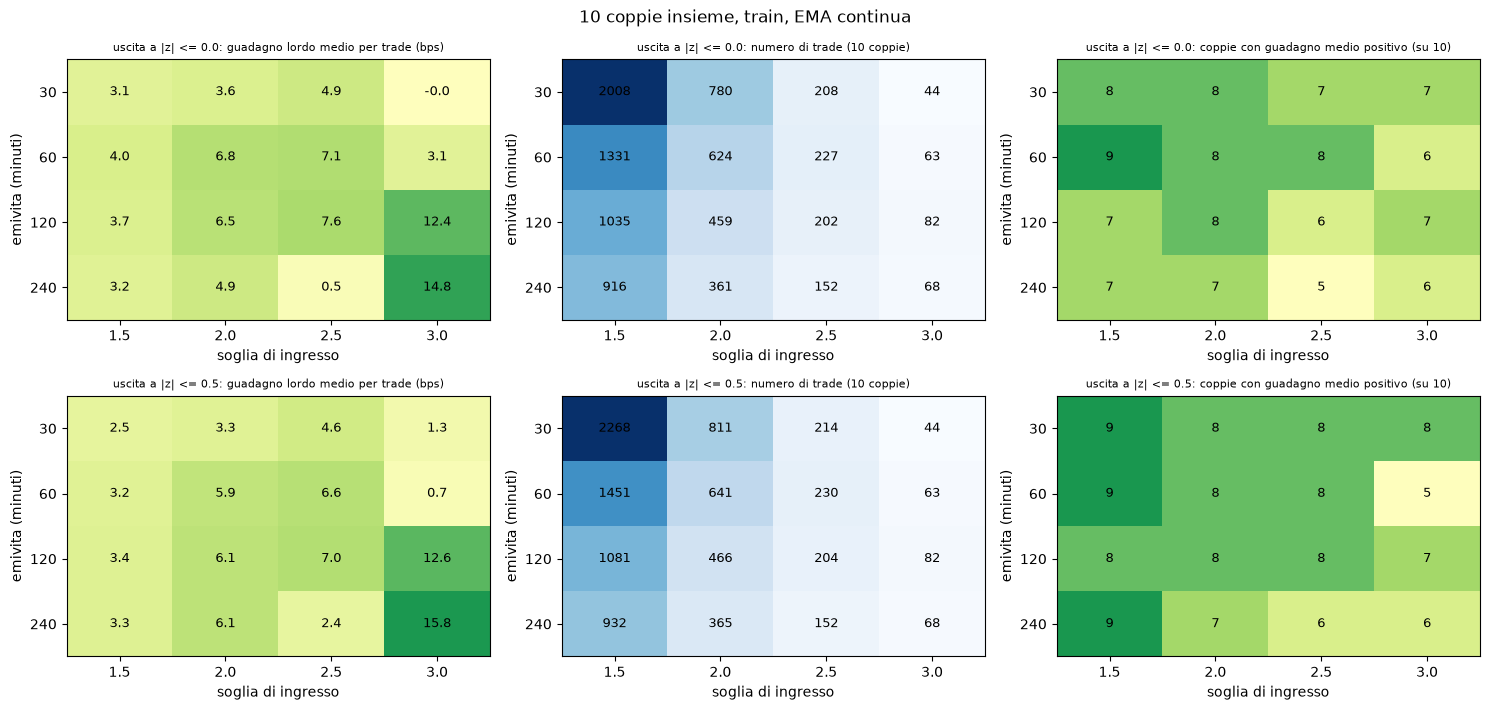

In [4]:
def run_grid(reset_daily):
    rows = []
    for p, d in data.items():
        for hl in GRID_HL:
            z = zscore(d.S, hl, reset_daily)
            for entry in GRID_ENTRY:
                for exit_ in GRID_EXIT:
                    tr, blocked = run_rules(d, z, entry, exit_)
                    rows.append(dict(pair=p, hl=hl, entry=entry, exit=exit_, n=len(tr), blocked=blocked,
                                     sum_bps=tr.gross_bps.sum() if len(tr) else 0.0, wins=int((tr.gross_bps > 0).sum()) if len(tr) else 0))
    return pd.DataFrame(rows)

def pooled(grid):
    # una riga per combinazione, sommando le coppie: guadagno medio per trade sul totale e coppie con guadagno medio positivo
    g = grid.groupby(["hl", "entry", "exit"]).agg(n_trades=("n", "sum"), sum_bps=("sum_bps", "sum"), wins=("wins", "sum"), blocked=("blocked", "sum")).reset_index()
    g["mean_bps"] = g.sum_bps / g.n_trades
    g["win_rate"] = g.wins / g.n_trades
    per_pair_pos = grid.assign(m=grid.sum_bps / grid.n.replace(0, np.nan)).groupby(["hl", "entry", "exit"]).m.apply(lambda s: int((s > 0).sum()))
    g = g.merge(per_pair_pos.rename("coppie_positive").reset_index(), on=["hl", "entry", "exit"])
    return g

grid_cont_pairs = run_grid(reset_daily=False)
grid_cont = pooled(grid_cont_pairs)

def show_grid(grid, title):
    fig, ax = plt.subplots(len(GRID_EXIT), 3, figsize=(15, 3.6 * len(GRID_EXIT)))
    for r, ex in enumerate(GRID_EXIT):
        g = grid[grid.exit == ex]
        for c, (col, name, cmap, lim) in enumerate([("mean_bps", "guadagno lordo medio per trade (bps)", "RdYlGn", 20), ("n_trades", "numero di trade (10 coppie)", "Blues", None),
                                                    ("coppie_positive", "coppie con guadagno medio positivo (su 10)", "RdYlGn", None)]):
            p = g.pivot(index="hl", columns="entry", values=col)
            im = ax[r, c].imshow(p.values, cmap=cmap, aspect="auto", vmin=(-lim if lim else (0 if col == "coppie_positive" else None)), vmax=(lim if lim else (10 if col == "coppie_positive" else None)))
            ax[r, c].set_xticks(range(len(p.columns)), p.columns); ax[r, c].set_yticks(range(len(p.index)), p.index)
            ax[r, c].set_xlabel("soglia di ingresso"); ax[r, c].set_ylabel("emivita (minuti)"); ax[r, c].set_title(f"uscita a |z| <= {ex}: {name}", fontsize=8)
            for (y, x), v in np.ndenumerate(p.values):
                ax[r, c].text(x, y, f"{v:.0f}" if col != "mean_bps" else f"{v:.1f}", ha="center", va="center", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_grid(grid_cont, "10 coppie insieme, train, EMA continua")

In [5]:
def choose(grid):
    # regola dichiarata: tra le combinazioni con almeno MIN_TRADES_POOLED trade, guadagno lordo medio più alto; poi controllo dei vicini
    ok = grid[grid.n_trades >= MIN_TRADES_POOLED]
    best = ok.sort_values("mean_bps", ascending=False).iloc[0]
    i_hl, i_en = GRID_HL.index(best.hl), GRID_ENTRY.index(best.entry)
    neigh = [(GRID_HL[a], GRID_ENTRY[b]) for a in range(max(0, i_hl - 1), min(len(GRID_HL), i_hl + 2))
             for b in range(max(0, i_en - 1), min(len(GRID_ENTRY), i_en + 2)) if (a, b) != (i_hl, i_en)]
    nb = grid[(grid.exit == best.exit) & pd.Series(list(zip(grid.hl, grid.entry)), index=grid.index).isin(neigh)]
    return best, nb

best, neighbours = choose(grid_cont)
print(f"combinazioni con almeno {MIN_TRADES_POOLED} trade: {(grid_cont.n_trades >= MIN_TRADES_POOLED).sum()} su {len(grid_cont)}")
print(f"SCELTA (uguale per tutte le coppie) -> emivita {best.hl:.0f}, ingresso {best.entry}, uscita {best.exit}: {best.n_trades:.0f} trade, lordo medio {best.mean_bps:.1f} bps, "
      f"in positivo {best.win_rate:.0%}, coppie con guadagno positivo {best.coppie_positive:.0f} su 10")
print(f"combinazioni vicine: {len(neighbours)}, con guadagno medio positivo: {(neighbours.mean_bps > 0).sum()}; guadagno medio delle vicine {neighbours.mean_bps.mean():.1f} bps")
grid_cont.sort_values("mean_bps", ascending=False).head(8).round(2)

combinazioni con almeno 300 trade: 16 su 32
SCELTA (uguale per tutte le coppie) -> emivita 60, ingresso 2.0, uscita 0.0: 624 trade, lordo medio 6.8 bps, in positivo 59%, coppie con guadagno positivo 8 su 10
combinazioni vicine: 8, con guadagno medio positivo: 8; guadagno medio delle vicine 5.1 bps


,hl,entry,exit,n_trades,sum_bps,wins,blocked,mean_bps,win_rate,coppie_positive
31,240,3.0,0.5,68,1074.09,40,23,15.80,0.59,6
30,240,3.0,0.0,68,1006.02,40,23,14.79,0.59,6
23,120,3.0,0.5,82,1036.81,46,22,12.64,0.56,7
22,120,3.0,0.0,82,1017.62,46,22,12.41,0.56,7
20,120,2.5,0.0,202,1525.57,109,61,7.55,0.54,6
12,60,2.5,0.0,227,1618.68,131,73,7.13,0.58,8
21,120,2.5,0.5,204,1429.83,114,62,7.01,0.56,8
10,60,2.0,0.0,624,4226.20,371,183,6.77,0.59,8


**Lettura.** 
- **Scelta: emivita 60 minuti, ingresso 2.0, uscita 0.** 624 trade, 6.8 punti base lordi in media, 8 coppie su 10 con guadagno positivo, 8 combinazioni vicine su 8 positive (in media 5.1). È **diversa da quella di MA-V** (emivita 120): non è un problema, perché la differenza tra le due scelte su MA-V è piccola (con emivita 60 MA-V fa 7.5 bps su 75 trade, contro 10.3 su 56 con la sua scelta).
- Come già visto su MA-V, **il guadagno medio sale con la soglia di ingresso ma i trade diminuiscono**: a soglia 3.0 si arriva a 12-16 bps ma con 68-82 trade e solo 6-7 coppie su 10 positive; a soglia 2.5 sono circa 200-230 trade e 7 bps. La regola del minimo di 300 trade evita di scegliere la combinazione più alta, che si basa su pochissimi trade.
- Il guadagno è **lordo**: senza costi.

## 5. Risultati con i parametri scelti, coppia per coppia

Si bloccano i parametri e si guarda **ogni coppia**: quanti trade, quanto guadagno lordo, quanto è incerto (errore standard). Il guadagno è **lordo**, senza costi (Passaggio 6). L'errore standard assume trade indipendenti; in realtà trade di coppie dello stesso settore nello stesso giorno sono legati, quindi l'incertezza vera è un po' maggiore.

In [6]:
HL, ENTRY, EXIT = int(best.hl), float(best.entry), float(best.exit)
all_trades, rows = [], []
for p, d in data.items():
    tr, blocked = run_rules(d, zscore(d.S, HL), ENTRY, EXIT)
    all_trades.append(tr)
    n_days = info.loc[p, "giorni_train"]
    rows.append(dict(pair=p, trade=len(tr), per_giorno=len(tr) / n_days, lordo_medio_bps=tr.gross_bps.mean(), errore_std_bps=tr.gross_bps.std() / np.sqrt(len(tr)) if len(tr) > 1 else np.nan,
                     in_positivo=(tr.gross_bps > 0).mean(), uscita_per_tempo=(tr.exit_reason == "tempo").mean(), scartate_gamba_ferma=blocked, prezzo_esec_vecchio=int(tr.exec_price_stale.sum())))
trades = pd.concat(all_trades, ignore_index=True)
per_pair = pd.DataFrame(rows).set_index("pair")

print(f"Parametri bloccati (uguali per tutte): emivita {HL} minuti, ingresso |z| >= {ENTRY}, uscita |z| <= {EXIT}, stop |z| >= {ENTRY + STOP_EXTRA}, tempo massimo {MAX_HOLD} minuti")
print(f"TOTALE: {len(trades)} trade, lordo medio {trades.gross_bps.mean():.1f} bps (errore standard {trades.gross_bps.std() / np.sqrt(len(trades)):.1f}), mediano {trades.gross_bps.median():.1f}, in positivo {(trades.gross_bps > 0).mean():.0%}")
print(f"coppie con guadagno medio positivo: {(per_pair.lordo_medio_bps > 0).sum()} su 10; barre candidate scartate per gamba ferma: {per_pair.scartate_gamba_ferma.sum()}")
per_pair.style.format({"per_giorno": "{:.2f}", "lordo_medio_bps": "{:.1f}", "errore_std_bps": "{:.1f}", "in_positivo": "{:.0%}", "uscita_per_tempo": "{:.0%}"})

Parametri bloccati (uguali per tutte): emivita 60 minuti, ingresso |z| >= 2.0, uscita |z| <= 0.0, stop |z| >= 3.5, tempo massimo 90 minuti
TOTALE: 624 trade, lordo medio 6.8 bps (errore standard 2.1), mediano 10.4, in positivo 59%
coppie con guadagno medio positivo: 8 su 10; barre candidate scartate per gamba ferma: 183


,trade,per_giorno,lordo_medio_bps,errore_std_bps,in_positivo,uscita_per_tempo,scartate_gamba_ferma,prezzo_esec_vecchio
pair,,,,,,,,
MA-V,75,1.17,7.5,2.5,64%,36%,5,1
TFC-USB,64,1.07,-1.6,4.0,61%,41%,6,2
BAC-PNC,62,0.97,-3.8,6.6,50%,39%,31,20
CSX-UNP,61,1.02,6.8,4.2,56%,41%,40,25
PYPL-XYZ,60,0.94,29.6,14.0,63%,47%,1,3
BNY-GS,51,0.85,9.6,8.5,61%,49%,33,18
HD-LOW,65,1.08,4.4,4.1,68%,31%,35,12
ITW-OTIS,54,0.84,3.2,5.7,50%,56%,26,15
MCD-YUM,64,1.00,9.7,6.9,59%,45%,5,15


Motivo di uscita (totale):
               trade  lordo medio (bps)
exit_reason                            
fine_giornata     42              -16.1
rientro          301               37.1
stop              14              -38.1
tempo            267              -21.5

Fascia oraria dell'ingresso, minuti dall'apertura (totale):
         trade  lordo medio (bps)
fascia                           
15-30      271               12.4
30-60       87                4.3
60-120      66               10.3
120-240     69               -1.1
240-390    131               -0.9


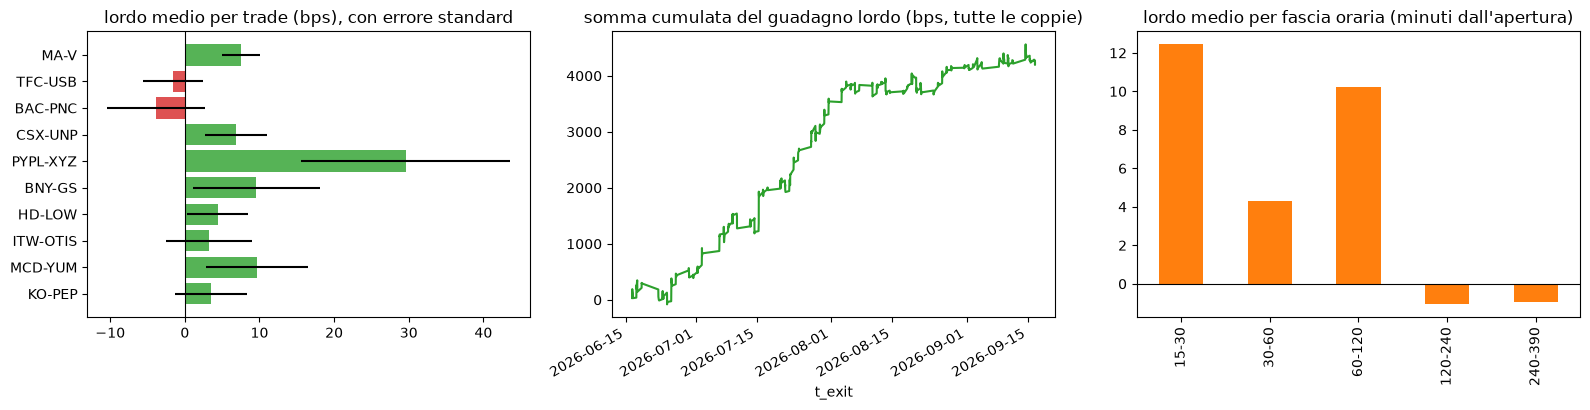

In [7]:
trades["fascia"] = pd.cut(trades.minute_of_day, [0, 30, 60, 120, 240, 390], right=True, labels=["15-30", "30-60", "60-120", "120-240", "240-390"], include_lowest=True)
print("Motivo di uscita (totale):"); print(trades.groupby("exit_reason").gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"}))
print("\nFascia oraria dell'ingresso, minuti dall'apertura (totale):"); print(trades.groupby("fascia", observed=False).gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"}))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].barh(per_pair.index, per_pair.lordo_medio_bps, xerr=per_pair.errore_std_bps, color=np.where(per_pair.lordo_medio_bps > 0, "tab:green", "tab:red"), alpha=0.8)
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("lordo medio per trade (bps), con errore standard"); ax[0].invert_yaxis()
trades.sort_values("t_exit").set_index("t_exit").gross_bps.cumsum().plot(ax=ax[1], color="tab:green"); ax[1].set_title("somma cumulata del guadagno lordo (bps, tutte le coppie)")
trades.groupby("fascia", observed=False).gross_bps.mean().plot.bar(ax=ax[2], color="tab:orange"); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("lordo medio per fascia oraria (minuti dall'apertura)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

In [8]:
# tre controlli su da dove viene il guadagno
st = trades.groupby("exec_price_stale").gross_bps.agg(["size", "mean"]).round(1).rename(columns={"size": "trade", "mean": "lordo medio (bps)"})
st.index = st.index.map({False: "esecuzione a un prezzo di scambio vero", True: "esecuzione a un prezzo vecchio (barra t+1 riempita)"})
print(st.to_string())

rest = trades[trades.pair != "PYPL-XYZ"]
print(f"\nsenza PYPL-XYZ (la coppia col guadagno più alto): {len(rest)} trade, lordo medio {rest.gross_bps.mean():.1f} bps (errore standard {rest.gross_bps.std() / np.sqrt(len(rest)):.1f}), coppie positive {(per_pair.drop('PYPL-XYZ').lordo_medio_bps > 0).sum()} su 9")

early = trades[trades.minute_of_day <= 30]
print(f"\nentrate nei minuti 15-30: {len(early)} trade su {len(trades)} ({len(early) / len(trades):.0%}), {early.gross_bps.sum() / trades.gross_bps.sum():.0%} del guadagno lordo totale, lordo medio {early.gross_bps.mean():.1f} bps")
late = trades[trades.minute_of_day > 30]
print(f"entrate dopo i 30 minuti dall'apertura: {len(late)} trade, lordo medio {late.gross_bps.mean():.1f} bps (errore standard {late.gross_bps.std() / np.sqrt(len(late)):.1f})")
print(f"segnali che coincidono nel tempo: il {trades.groupby('t_signal').pair.transform('size').gt(1).mean():.0%} dei trade ha almeno un segnale di un'altra coppia nello stesso minuto")

                                                     trade  lordo medio (bps)
exec_price_stale                                                             
esecuzione a un prezzo di scambio vero                 513                6.7
esecuzione a un prezzo vecchio (barra t+1 riempita)    111                7.3

senza PYPL-XYZ (la coppia col guadagno più alto): 564 trade, lordo medio 4.3 bps (errore standard 1.8), coppie positive 7 su 9

entrate nei minuti 15-30: 271 trade su 624 (43%), 80% del guadagno lordo totale, lordo medio 12.4 bps
entrate dopo i 30 minuti dall'apertura: 353 trade, lordo medio 2.4 bps (errore standard 2.1)
segnali che coincidono nel tempo: il 25% dei trade ha almeno un segnale di un'altra coppia nello stesso minuto


**Lettura.** 
- **Totale**: 624 trade (circa uno al giorno per coppia, dieci al giorno in tutto), 6.8 bps lordi con errore standard 2.1 (circa 3 errori standard), mediano 10.4, 59% in positivo.
- **Non dipende da una coppia sola, ma una pesa molto**: 8 coppie su 10 positive, ma solo MA-V (7.5, errore 2.5) e PYPL-XYZ (29.6, errore 14.0) hanno un risultato di 2-3 errori standard; le altre sono tra -3.8 e +9.7 con errori di 4-8 bps, cioè indistinguibili da zero. **Senza PYPL-XYZ** i trade sono 564 e il guadagno medio scende a **4.3 bps** (errore 1.8), con 7 coppie su 9 positive.
- **Come escono i trade**: solo il 48% rientra (301 su 624) e guadagna in media 37 bps; i 267 trade che arrivano al tempo massimo perdono in media 21 bps, i 14 stop 38 bps, i 42 chiusi a fine giornata 16. Il guadagno complessivo è positivo perché le vincite dei rientri sono più grandi delle perdite degli altri. Attenzione: chi rientra esce prima, quindi il guadagno dei rientri è alto per costruzione.
- **Il guadagno viene quasi tutto dall'inizio della giornata**: 271 trade (43%) entrano tra i minuti 15 e 30 dall'apertura e producono l'**80% del guadagno lordo totale** (12.4 bps in media). Dopo i primi 30 minuti 353 trade fanno solo 2.4 bps (errore 2.1), indistinguibile da zero. È lo stesso effetto visto su MA-V: con l'EMA continua il gap della notte lascia lo z-score alto all'apertura e si scommette sul suo rientro. Il segnale "dentro la giornata" è debole.
- **Prezzi di esecuzione vecchi**: 111 trade su 624 (18%) sono eseguiti alla barra successiva quando questa è riempita, cioè a un prezzo che non è di uno scambio vero; in più 183 barre candidate sono state scartate per la gamba ferma. Il guadagno di questi trade è simile agli altri (7.3 contro 6.7 bps), quindi non vediamo un'inflazione, ma per le coppie con la gamba ferma più spesso (BAC-PNC 20 trade su 62, CSX-UNP 25 su 61, BNY-GS 18 su 51) il guadagno al minuto è meno credibile come guadagno realizzabile. **[APERTO]** decisione B del Passaggio 2: segnale su barre da 5 minuti per queste coppie.
- **I segnali delle coppie coincidono nel tempo**: il 25% dei trade ha un segnale di un'altra coppia nello stesso minuto (spesso è un movimento di tutto il mercato). I trade quindi non sono indipendenti e gli errori standard sono più piccoli del reale.

## 6. Parametri scelti coppia per coppia (solo informativo)

Cosa succederebbe se ogni coppia avesse **i suoi parametri**, scelti sul train con la stessa regola (almeno `MIN_TRADES_OWN` = 20 trade, guadagno medio più alto)? Questa tabella **non viene usata**: serve a vedere quanto la scelta comune sia lontana da quella migliore per ogni coppia, e a decidere se vale la pena scegliere per coppia (`Programma.md`). Attenzione: il guadagno nella colonna "migliore" è **in-sample**, scelto guardando gli stessi dati su cui è misurato, quindi è per costruzione più alto e più ottimistico di quello che si vedrebbe nel test.

In [9]:
rows = []
for p in data:
    g = grid_cont_pairs[(grid_cont_pairs.pair == p)].assign(mean_bps=lambda x: x.sum_bps / x.n.replace(0, np.nan))
    common = g[(g.hl == HL) & (g.entry == ENTRY) & (g.exit == EXIT)].iloc[0]
    ok = g[g.n >= MIN_TRADES_OWN]
    if len(ok):
        b = ok.sort_values("mean_bps", ascending=False).iloc[0]
        rows.append(dict(pair=p, comune_trade=common.n, comune_bps=common.mean_bps, migliore_hl=b.hl, migliore_ingresso=b.entry, migliore_uscita=b.exit, migliore_trade=b.n, migliore_bps=b.mean_bps))
    else:
        rows.append(dict(pair=p, comune_trade=common.n, comune_bps=common.mean_bps))
own = pd.DataFrame(rows).set_index("pair")
own.style.format({"comune_bps": "{:.1f}", "migliore_bps": "{:.1f}", "comune_trade": "{:.0f}", "migliore_trade": "{:.0f}", "migliore_hl": "{:.0f}"}, na_rep="-")

,comune_trade,comune_bps,migliore_hl,migliore_ingresso,migliore_uscita,migliore_trade,migliore_bps
pair,,,,,,,
MA-V,75,7.5,60,2.500000,0.000000,28,13.5
TFC-USB,64,-1.6,30,2.500000,0.500000,26,2.7
BAC-PNC,62,-3.8,30,1.500000,0.000000,204,3.0
CSX-UNP,61,6.8,120,2.000000,0.000000,52,14.9
PYPL-XYZ,60,29.6,120,2.500000,0.000000,25,41.6
BNY-GS,51,9.6,60,2.000000,0.000000,51,9.6
HD-LOW,65,4.4,30,2.500000,0.000000,20,8.5
ITW-OTIS,54,3.2,30,2.000000,0.000000,66,7.8
MCD-YUM,64,9.7,60,2.500000,0.500000,24,31.2


**Lettura.** 
I parametri migliori **cambiano molto da coppia a coppia** (emivita da 30 a 120 minuti, ingresso da 1.5 a 2.5, uscita 0 o 0.5), senza un andamento chiaro: è più probabile rumore che coppie con "caratteristiche" diverse. Il guadagno "migliore" è misurato sugli stessi dati su cui è scelto (in-sample), quindi è più alto per costruzione, e spesso su pochi trade: per esempio MCD-YUM sale da 9.7 a 31.2 bps con 24 trade, PYPL-XYZ da 29.6 a 41.6 con 25. BAC-PNC, negativa con i parametri comuni (-3.8), passa a +3.0 ma solo con soglia 1.5 e 204 trade. **Teniamo i parametri comuni.** La scelta per coppia resta possibile, ma va giustificata con un test fuori campione e con più dati.

## 7. Confronto: EMA azzerata ogni giorno

La stessa griglia e la stessa regola di scelta con la EMA che riparte ogni mattina (alternativa descritta in `segnale_mav.ipynb`). Serve a vedere se la scelta della EMA continua, fatta su MA-V, regge sulle 10 coppie. **Non è l'alternativa adottata.**

In [10]:
grid_reset_pairs = run_grid(reset_daily=True)
grid_reset = pooled(grid_reset_pairs)
best_r, neigh_r = choose(grid_reset)
print(f"EMA azzerata, stessa regola -> emivita {best_r.hl:.0f}, ingresso {best_r.entry}, uscita {best_r.exit}: {best_r.n_trades:.0f} trade, lordo medio {best_r.mean_bps:.1f} bps, coppie positive {best_r.coppie_positive:.0f} su 10")
print(f"combinazioni vicine con guadagno positivo: {(neigh_r.mean_bps > 0).sum()} su {len(neigh_r)}")
cmp = pd.DataFrame({
    "EMA continua": grid_cont[grid_cont.n_trades >= MIN_TRADES_POOLED].mean_bps.describe()[["count", "mean", "max"]],
    "EMA azzerata": grid_reset[grid_reset.n_trades >= MIN_TRADES_POOLED].mean_bps.describe()[["count", "mean", "max"]],
}).rename(index={"count": f"combinazioni con >= {MIN_TRADES_POOLED} trade", "mean": "lordo medio (bps), media delle combinazioni", "max": "lordo medio massimo"}).round(1)
cmp

EMA azzerata, stessa regola -> emivita 60, ingresso 2.0, uscita 0.0: 792 trade, lordo medio 1.5 bps, coppie positive 7 su 10
combinazioni vicine con guadagno positivo: 5 su 8


,EMA continua,EMA azzerata
combinazioni con >= 300 trade,16.0,16.0
"lordo medio (bps), media delle combinazioni",4.3,0.8
lordo medio massimo,6.8,1.5


**Lettura.** 
Con la EMA azzerata ogni mattina, la migliore combinazione (stessa regola di scelta) dà **1.5 bps lordi** su 792 trade (7 coppie su 10 positive, 5 vicine su 8 positive), contro 6.8 con la EMA continua; in media sulle 16 combinazioni valide 0.8 contro 4.3. Il risultato conferma quello di MA-V: la EMA continua rende di più, ed è coerente con il fatto che l'80% del suo guadagno viene dalle entrate nei minuti 15-30, quando il gap della notte è ancora nello z-score. Senza quel gap (EMA azzerata) il guadagno lordo medio è vicino a zero.

## 8. Salvataggio dei segnali del train

Tabella dei segnali di tutte le coppie con i parametri bloccati: è l'input del Passaggio 5 (agente di notizie). Colonne: `pair`, `ticker_A` e `ticker_B`, orari del segnale, dell'ingresso e dell'uscita (ora di New York), `direction`, `z_signal`, `leg_piu_mosso` (descrittivo) e i rendimenti degli ultimi 30 minuti, prezzi di ingresso e uscita, `exit_reason`, `gross_bps` (lordo, senza costi), `exec_price_stale`, parametri usati. Cartella ignorata da git: chi la vuole rilancia il notebook. Il file di MA-V di `segnale_mav.ipynb` resta com'era.

In [11]:
out = trades.sort_values(["t_signal", "pair"]).reset_index(drop=True)
out["signal_id"] = out.index
out["ema"] = "continua"
out["hl_min"], out["entry_z"], out["exit_z"], out["stop_z"] = HL, ENTRY, EXIT, ENTRY + STOP_EXTRA
cols = ["signal_id", "pair", "ticker_A", "ticker_B", "t_signal", "t_entry", "t_exit", "direction", "z_signal", "leg_piu_mosso", "ret_A_30m", "ret_B_30m",
        "price_A_in", "price_B_in", "price_A_out", "price_B_out", "exit_reason", "gross_bps", "minutes_in_trade", "exec_price_stale", "ema", "hl_min", "entry_z", "exit_z", "stop_z"]
assert out.t_exit.max() < pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), "il file dei segnali contiene giorni di test"
OUT_SIGNALS.parent.mkdir(parents=True, exist_ok=True)
out[cols].to_csv(OUT_SIGNALS, index=False)
print(f"salvati {len(out)} segnali di {out.pair.nunique()} coppie in {OUT_SIGNALS} (ultimo giorno: {out.t_exit.max().date()}, taglio del train: {TRAIN_END})")
out[cols].head()

salvati 624 segnali di 10 coppie in ../data/processed/signals_10pairs_train.csv (ultimo giorno: 2026-09-16, taglio del train: 2026-09-16)


,signal_id,pair,ticker_A,ticker_B,t_signal,t_entry,t_exit,direction,z_signal,leg_piu_mosso,...,price_B_out,exit_reason,gross_bps,minutes_in_trade,exec_price_stale,ema,hl_min,entry_z,exit_z,stop_z
0,0,MCD-YUM,MCD,YUM,2026-06-16 10:54:00,2026-06-16 10:55:00,2026-06-16 12:25:00,short MCD / long YUM,2.003566,YUM,...,158.000,tempo,-24.768999,90.0,False,continua,60,2.0,0.0,3.5
1,1,KO-PEP,KO,PEP,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:19:00,short KO / long PEP,2.035824,PEP,...,145.650,rientro,31.056741,14.0,False,continua,60,2.0,0.0,3.5
2,2,MA-V,MA,V,2026-06-16 11:04:00,2026-06-16 11:05:00,2026-06-16 11:23:00,short MA / long V,2.073157,MA,...,330.275,rientro,25.179270,18.0,False,continua,60,2.0,0.0,3.5
3,3,ITW-OTIS,ITW,OTIS,2026-06-16 11:14:00,2026-06-16 11:15:00,2026-06-16 12:03:00,long ITW / short OTIS,-2.165016,OTIS,...,73.460,rientro,37.406280,48.0,True,continua,60,2.0,0.0,3.5
4,4,BNY-GS,BNY,GS,2026-06-16 11:45:00,2026-06-16 11:46:00,2026-06-16 12:22:00,short BNY / long GS,2.226346,GS,...,1096.430,rientro,57.267261,36.0,False,continua,60,2.0,0.0,3.5


## 9. Conclusioni e cose aperte

I numeri sono quelli dell'esecuzione sul train (16 giugno - 16 settembre 2026) delle 10 coppie, con parametri uguali per tutte. Se si cambiano i parametri o i dati, vanno riaggiornati.

### Parametri scelti (uguali per tutte, EMA continua, β = 1)
Emivita 60 minuti, ingresso a $|z| \ge 2.0$, uscita a $|z| \le 0$, stop a $|z| \ge 3.5$, tempo massimo 90 minuti, nessun ingresso nei primi 15 e negli ultimi 30 minuti.

### Risultati sul train
| | |
|---|---|
| Trade | **624** (circa 1 al giorno per coppia) |
| Guadagno **lordo** medio per trade | **6.8 bps** (errore standard 2.1; mediano 10.4; 59% in positivo) |
| Senza PYPL-XYZ | 564 trade, 4.3 bps (errore 1.8), 7 coppie su 9 positive |
| Coppie con guadagno medio positivo | 8 su 10 |
| Combinazioni vicine con guadagno positivo | 8 su 8 |
| Con EMA azzerata ogni giorno | 1.5 bps (792 trade) |
| Controllo di coerenza | su MA-V riproduce esattamente i 56 trade di `segnale_mav.ipynb` |

### Cosa ci dicono
1. **Il segnale si ripete sulle altre coppie ma è piccolo e fragile.** Circa 7 bps lordi per trade, 4 senza la coppia migliore. I costi di trading (4 operazioni per trade) non sono inclusi: su questi valori il margine è stretto.
2. **Quasi tutto il guadagno viene dai primi 30 minuti.** Le entrate dei minuti 15-30 (43% dei trade) producono l'80% del guadagno lordo; dopo i primi 30 minuti il guadagno è 2.4 bps, non distinguibile da zero. È il rientro del gap della notte, reso visibile dalla EMA continua. **[APERTO]** Decidere se è una strategia che vogliamo (e scriverla nel report con questo nome) o se va esclusa spostando in avanti l'inizio degli ingressi.
3. **Il rientro è lento e solo la metà dei trade rientra.** L'emivita dello spread va da 3 a 10 giorni, e solo il 48% dei trade rientra entro 90 minuti; chi non rientra perde in media 21 bps. Il tempo massimo di 90 minuti non è stato ottimizzato. **[APERTO]**
4. **La cointegrazione intraday non si conferma** per 9 coppie su 10 nel train (solo MA-V ha Engle-Granger sotto 0.05). La selezione del Passaggio 1 era fatta sui dati giornalieri su 20 anni, e questo test intraday è su solo 3 mesi: i due risultati non si contraddicono, ma indicano che la relazione non è abbastanza forte sull'orizzonte di una giornata.
5. **Problema delle barre riempite**: cinque coppie hanno la gamba ferma in più del 40% dei minuti; 111 trade su 624 (18%) sono eseguiti a un prezzo vecchio e 183 occasioni sono scartate. Per quelle coppie il minuto è un'unità di tempo troppo piccola.
6. **Parametri per coppia: non conviene per ora.** I migliori cambiano da coppia a coppia senza un andamento chiaro e sono misurati in-sample (parte 6).

### Cose aperte
1. **Gap della notte / orario di ingresso** (punto 2): tenere o escludere.
2. **Decisione B del Passaggio 2**: segnale a 5 minuti per le coppie con la gamba ferma (BAC-PNC, CSX-UNP, BNY-GS, ITW-OTIS, MCD-YUM, HD-LOW), oppure tenerle al minuto dichiarando il limite.
3. **Parametri comuni o per coppia**: comuni per ora; la scelta per coppia è possibile (parte 6).
4. **Parametri non ottimizzati**: tempo massimo, stop, orari di esclusione (`OPEN_SKIP`, `CLOSE_SKIP`).
5. **Costi** (Passaggio 6): sono la prova decisiva per capire se i 4-7 bps lordi sopravvivono.
6. **Test (dal 17 settembre)**: non calcolato; si usa una sola volta con i parametri bloccati qui.

### Limiti da dichiarare nel report
- Circa 3 mesi di dati, un solo tipo di mercato.
- 32 combinazioni provate: rischio di test multipli (mitigato da minimo di trade, vicini positivi e test finale).
- Errori standard sottostimati: i trade non sono indipendenti (il 25% ha un segnale di un'altra coppia nello stesso minuto, e coppie dello stesso settore si muovono insieme).
- Guadagni lordi: niente costi, impatto sul prezzo, costo di prestito dei titoli.
- Prezzi non aggiustati per i dividendi (limite del Passaggio 2); prezzi di esecuzione vecchi nel 18% dei trade.